# ENSP355 – AI in Cyber Security | Lab 4
## Explainable and Privacy-Aware AI Threat Alert
**K.R. Mangalam University – School of Engineering & Technology** | COs: CO2, CO5 | Total: 50 marks

**Name:** _your name_ &nbsp;&nbsp; **Roll No.:** _your roll no._ &nbsp;&nbsp; **Section:** _your section_

> All records are sanitized, fictional samples (private IP ranges). No live system is tested.

## Setup: reuse the Lab 2 login-activity model
Lab 4 reuses the small Decision Tree from Lab 2. It is retrained here on `login_activity.csv` (38 labelled records: `Normal` / `Suspicious`) so the notebook runs on its own.

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, export_text

for path in ['login_activity.csv', 'data/login_activity.csv', '../data/login_activity.csv']:
    if os.path.exists(path):
        DATA_PATH = path
        break
else:
    try:                                    # Google Colab: upload the CSV manually
        from google.colab import files
        files.upload()
        DATA_PATH = 'login_activity.csv'
    except ImportError:
        raise FileNotFoundError('login_activity.csv not found')

RESULTS_DIR = '../results' if os.path.isdir('../results') else '.'

train = pd.read_csv(DATA_PATH)
features = ['failed_logins', 'login_hour', 'new_device', 'download_mb']

model = DecisionTreeClassifier(max_depth=2, random_state=42)   # small, explainable tree
model.fit(train[features], train['label'])

print('Training records :', len(train))
print('Training accuracy:', round(model.score(train[features], train['label']), 3))
print()
print(export_text(model, feature_names=features, show_weights=True))

Training records : 38
Training accuracy: 0.974

|--- failed_logins <= 3.50
|   |--- download_mb <= 625.00
|   |   |--- weights: [23.00, 0.00] class: Normal
|   |--- download_mb >  625.00
|   |   |--- weights: [1.00, 2.00] class: Suspicious
|--- failed_logins >  3.50
|   |--- weights: [0.00, 12.00] class: Suspicious



## Q1. Baseline Predictions with Confidence (5 marks)
**Aim:** run the model on five sanitized records and show the prediction with its confidence (the maximum class probability).

In [2]:
samples = pd.DataFrame([
    {'account_id': 'ACC-1001', 'ip_address': '192.168.10.24',
     'failed_logins': 0, 'login_hour': 10, 'new_device': 0, 'download_mb': 40},
    {'account_id': 'ACC-1002', 'ip_address': '10.0.4.18',
     'failed_logins': 7, 'login_hour': 2,  'new_device': 1, 'download_mb': 150},
    {'account_id': 'ACC-1003', 'ip_address': '172.16.8.90',
     'failed_logins': 1, 'login_hour': 15, 'new_device': 0, 'download_mb': 720},
    {'account_id': 'ACC-1004', 'ip_address': '192.168.20.11',
     'failed_logins': 4, 'login_hour': 23, 'new_device': 1, 'download_mb': 400},
    {'account_id': 'ACC-1005', 'ip_address': '10.1.1.9',
     'failed_logins': 2, 'login_hour': 9,  'new_device': 0, 'download_mb': 80}
])

samples['prediction'] = model.predict(samples[features])
samples['confidence'] = model.predict_proba(samples[features]).max(axis=1).round(3)
display(samples)

lowest = samples.loc[samples['confidence'].idxmin()]
print('Lowest-confidence record:', lowest['account_id'],
      '->', lowest['prediction'], 'with confidence', lowest['confidence'])

,account_id,ip_address,failed_logins,login_hour,new_device,download_mb,prediction,confidence
0,ACC-1001,192.168.10.24,0,10,0,40,Normal,1.000
1,ACC-1002,10.0.4.18,7,2,1,150,Suspicious,1.000
2,ACC-1003,172.16.8.90,1,15,0,720,Suspicious,0.667
3,ACC-1004,192.168.20.11,4,23,1,400,Suspicious,1.000
4,ACC-1005,10.1.1.9,2,9,0,80,Normal,1.000


Lowest-confidence record: ACC-1003 -> Suspicious with confidence 0.667


**Lowest-confidence record:** ACC-1003 (1 failed login, 15:00, known device, 720 MB download) – predicted *Suspicious* with confidence 0.667.

**Why confidence is not certainty:** confidence is only the share of training records in the tree leaf that had the predicted class (here 2 of 3). It says how consistent the training data was, not whether the login is truly malicious, so a human must still judge the case.

## Q2. Feature Importance and Explanation (10 marks)

,feature,importance
0,failed_logins,0.856
3,download_mb,0.144
1,login_hour,0.000
2,new_device,0.000


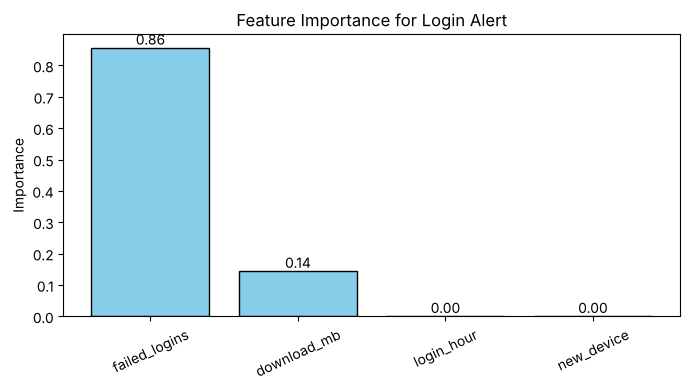


- failed_logins was the main feature: the tree first separates records with more than 3 failed logins, which are almost all Suspicious.
- download_mb was used next: among records with few failed logins, very large downloads (over about 625 MB) look more suspicious.
- login_hour was not used by this small tree, so it did not influence the model's decisions.


In [3]:
importance = pd.DataFrame({
    'feature': features,
    'importance': model.feature_importances_.round(3)
}).sort_values('importance', ascending=False)
display(importance)

plt.figure(figsize=(7, 4))
bars = plt.bar(importance['feature'], importance['importance'],
               color='skyblue', edgecolor='black')
for b in bars:                                           # value labels
    plt.text(b.get_x() + b.get_width() / 2, b.get_height(),
             f'{b.get_height():.2f}', ha='center', va='bottom')
plt.title('Feature Importance for Login Alert')
plt.ylabel('Importance')
plt.xticks(rotation=25)
plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/feature_importance.png', dpi=150)
plt.show()

explanations = {
    'failed_logins': 'was the main feature: the tree first separates records with more than 3 failed logins, which are almost all Suspicious.',
    'download_mb':   'was used next: among records with few failed logins, very large downloads (over about 625 MB) look more suspicious.',
    'login_hour':    'was not used by this small tree, so it did not influence the model\'s decisions.',
    'new_device':    'was not used by this small tree, so it did not influence the model\'s decisions.',
}
print()
for feature in importance.head(3)['feature']:
    print(f'- {feature} {explanations[feature]}')

**Top-three features in simple words**
1. **failed_logins** – the strongest signal; many failed attempts split the data most cleanly.
2. **download_mb** – a very large download helps separate the few suspicious records that have few failed logins.
3. **login_hour / new_device (tie at 0)** – the shallow tree never needed them. Both still appear in the alert *reasons* (Q5) because analysts care about them.

**Caution:** feature importance is a model-level summary of how the tree split this small dataset. It does **not** prove that a feature *causes* an attack, and a feature with importance 0 is not necessarily harmless – it may simply be unused by a shallow tree.

## Q3. Controlled Sensitivity Test (10 marks)
**Aim:** change exactly one input (`failed_logins`: 2 → 8) on ACC-1005 and compare the outputs.

In [4]:
baseline = samples.iloc[[4]].copy()
changed = baseline.copy()
changed['failed_logins'] = 8            # the ONLY change

baseline_prediction = model.predict(baseline[features])[0]
baseline_confidence = model.predict_proba(baseline[features]).max()
changed_prediction = model.predict(changed[features])[0]
changed_confidence = model.predict_proba(changed[features]).max()

print('Baseline:', baseline_prediction, baseline_confidence)
print('Changed :', changed_prediction, changed_confidence)

compare = pd.DataFrame({
    'case': ['Baseline', 'Changed'],
    'failed_logins': [baseline['failed_logins'].iloc[0], changed['failed_logins'].iloc[0]],
    'login_hour': baseline['login_hour'].iloc[0],
    'new_device': baseline['new_device'].iloc[0],
    'download_mb': baseline['download_mb'].iloc[0],
    'prediction': [baseline_prediction, changed_prediction],
    'confidence': [round(baseline_confidence, 3), round(changed_confidence, 3)],
})
display(compare)

Baseline: Normal 1.0
Changed : Suspicious 1.0


,case,failed_logins,login_hour,new_device,download_mb,prediction,confidence
0,Baseline,2,9,0,80,Normal,1.0
1,Changed,8,9,0,80,Suspicious,1.0


In [5]:
# Extra: where exactly does the decision flip? (all other features fixed)
rows = []
for n in range(0, 11):
    r = baseline[features].copy()
    r['failed_logins'] = n
    rows.append((n, model.predict(r)[0], round(model.predict_proba(r).max(), 3)))
display(pd.DataFrame(rows, columns=['failed_logins', 'prediction', 'confidence']))

,failed_logins,prediction,confidence
0,0,Normal,1.0
1,1,Normal,1.0
2,2,Normal,1.0
3,3,Normal,1.0
4,4,Suspicious,1.0
5,5,Suspicious,1.0
6,6,Suspicious,1.0
7,7,Suspicious,1.0
8,8,Suspicious,1.0
9,9,Suspicious,1.0


**Sensitivity interpretation**
- Only `failed_logins` changed (2 → 8); every other value stayed fixed.
- The decision changed from **Normal** to **Suspicious**, so the model is highly sensitive to this feature.
- The extra sweep shows a sharp threshold: the label flips between 3 and 4 failed logins (the tree split is at 3.5), not gradually.
- This is expected for a decision tree and matches the importance result (failed_logins ranks first). A sudden flip at one value is a reason for analyst review near the threshold.

## Q4. Privacy Masking and Responsible-Use Rules (5 marks)

In [6]:
def mask_ip(ip):
    parts = str(ip).split('.')
    if len(parts) == 4:
        return f'{parts[0]}.{parts[1]}.xxx.xxx'     # keep first two sections only
    return '<MASKED_IP>'

def mask_account(account_id):
    text = str(account_id)
    return text[:4] + '***' + text[-2:]             # ACC-1002 -> ACC-***02

samples['masked_ip'] = samples['ip_address'].apply(mask_ip)
samples['masked_account'] = samples['account_id'].apply(mask_account)

display(samples[['masked_account', 'masked_ip', 'prediction', 'confidence']])

privacy_rules = [
    'Mask identifiers before display or export.',
    'Use sanitized data in classroom notebooks.',
    'Restrict access to unmasked records.',
    'Require human review for high-risk action.'
]
for rule in privacy_rules:
    print('-', rule)

,masked_account,masked_ip,prediction,confidence
0,ACC-***01,192.168.xxx.xxx,Normal,1.000
1,ACC-***02,10.0.xxx.xxx,Suspicious,1.000
2,ACC-***03,172.16.xxx.xxx,Suspicious,0.667
3,ACC-***04,192.168.xxx.xxx,Suspicious,1.000
4,ACC-***05,10.1.xxx.xxx,Normal,1.000


- Mask identifiers before display or export.
- Use sanitized data in classroom notebooks.
- Restrict access to unmasked records.
- Require human review for high-risk action.


**Evidence:** the table above (and the final alert in Q5 and the exported CSV) show only `masked_account` and `masked_ip`; the raw `account_id` and `ip_address` columns are not displayed or exported after this step.

## Q5. Responsible Alert Generation (10 marks)

In [7]:
def numeric_reason(row):
    reasons = []
    if row['failed_logins'] >= 5:
        reasons.append('many failed logins')
    if row['new_device'] == 1:
        reasons.append('new device')
    if row['login_hour'] < 6 or row['login_hour'] > 22:
        reasons.append('unusual login time')
    if row['download_mb'] >= 500:
        reasons.append('large data download')
    return ', '.join(reasons) if reasons else 'no strong warning'

def make_alert(row):
    reason = numeric_reason(row)
    if row['prediction'] == 'Suspicious':
        severity = 'High'
        action = 'Verify, contain if required, and report.'
    elif row['confidence'] < 0.70:
        severity = 'Medium'
        action = 'Send for analyst review before action.'
    else:
        severity = 'Low'
        action = 'Continue normal monitoring.'
    human_review = 'Yes' if severity in ['High', 'Medium'] else 'No'
    return severity, reason, action, human_review

alerts = samples.apply(make_alert, axis=1)
samples[['severity', 'reason', 'recommended_action', 'human_review']] = \
    pd.DataFrame(alerts.tolist(), index=samples.index)

alert_table = samples[['masked_account', 'masked_ip', 'prediction', 'confidence',
                       'severity', 'reason', 'recommended_action', 'human_review']]
display(alert_table)

# Export MASKED data only (raw account_id / ip_address are never written to disk)
alert_table.to_csv(f'{RESULTS_DIR}/Lab4_Final_Alerts.csv', index=False)
print('Saved:', f'{RESULTS_DIR}/Lab4_Final_Alerts.csv')

,masked_account,masked_ip,prediction,confidence,severity,reason,recommended_action,human_review
0,ACC-***01,192.168.xxx.xxx,Normal,1.000,Low,no strong warning,Continue normal monitoring.,No
1,ACC-***02,10.0.xxx.xxx,Suspicious,1.000,High,"many failed logins, new device, unusual login ...","Verify, contain if required, and report.",Yes
2,ACC-***03,172.16.xxx.xxx,Suspicious,0.667,High,large data download,"Verify, contain if required, and report.",Yes
3,ACC-***04,192.168.xxx.xxx,Suspicious,1.000,High,"new device, unusual login time","Verify, contain if required, and report.",Yes
4,ACC-***05,10.1.xxx.xxx,Normal,1.000,Low,no strong warning,Continue normal monitoring.,No


Saved: ../results/Lab4_Final_Alerts.csv


In [8]:
# Extra: the Medium / uncertain branch. This small tree never gives a 'Normal' with
# confidence < 0.70 on our five samples, so we test make_alert() with an ILLUSTRATIVE record.
uncertain = pd.Series({'failed_logins': 1, 'login_hour': 13, 'new_device': 0,
                       'download_mb': 600, 'prediction': 'Normal', 'confidence': 0.62})
print(make_alert(uncertain))   # (severity, reason, action, human_review)

('Medium', 'large data download', 'Send for analyst review before action.', 'Yes')


**Final alert summary**
| Account | Prediction | Severity | Why | Human review |
|---|---|---|---|---|
| ACC-***01 | Normal | Low | no strong warning | No |
| ACC-***02 | Suspicious | High | many failed logins, new device, unusual login time | Yes |
| ACC-***03 | Suspicious (0.667) | High | large data download | Yes |
| ACC-***04 | Suspicious | High | new device, unusual login time | Yes |
| ACC-***05 | Normal | Low | no strong warning | No |

**Human-review condition:** review is required whenever severity is High or Medium (a Suspicious prediction, or confidence below 0.70). The prototype only recommends actions; it never blocks or punishes an account automatically.

**Limitation:** the model was trained on only 38 small, simple records and the reasons come from fixed thresholds that are separate from the model, so a reason can disagree with the model's actual split. Real login behaviour is far more varied, so results should not be trusted for real security decisions.

## Conclusion
This lab turned a basic Decision Tree into a more responsible alert. Confidence showed how sure the model was (lowest: 0.667 for ACC-1003), feature importance showed that `failed_logins` drives most decisions, and the controlled test showed a sharp flip from Normal to Suspicious when failed logins rose from 2 to 8. Masking removed unnecessary personal detail, and the final alert gives severity, reason, recommended action and human-review status. Explanations and confidence help analysts verify and take responsibility for decisions, but they are not proof, so humans stay in control.